# Stage 1 — Data: sanity checks

Checking the daily dataset from `src/data_loader.py` before modeling.

Data isn't committed. To rebuild: run the download functions in `src/data_loader.py`, then `build_daily_dataset()`.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if Path.cwd().name == "notebooks":
    os.chdir("..")

daily = pd.read_csv("data/processed/daily.csv", index_col=0, parse_dates=True)

BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 3.6), "axes.grid": True, "grid.color": "#e6e5e1",
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.2,
    "axes.edgecolor": MUTED, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titlelocation": "left", "axes.titlesize": 12, "axes.titlecolor": INK,
})

print(daily.shape)
daily.tail(3)

(5735, 13)


,open,high,low,close,vix,vix9d,vix3m,vvix,skew,ovx,dtb3,baa10y,move
Date,,,,,,,,,,,,,
2026-10-15,766.25000,772.869995,764.429993,771.789978,16.46,13.97,18.49,92.57,160.45,49.13,4.10,1.44,99.059998
2026-10-16,773.23999,773.250000,760.640015,763.250000,19.99,20.12,20.50,109.91,168.59,50.74,4.10,1.44,102.489998
2026-10-19,767.22998,770.460022,765.820007,766.479980,18.44,17.93,19.60,106.93,161.86,50.22,4.08,1.46,101.099998


## 1. Data sources and publication lags

Signal time is 4:30pm ET (after VIX's 4:15pm close and the Fed's ~4:15pm H.15 update).

In [2]:
sources = pd.DataFrame([
    ("close/open/high/low", "SPY prices, dividend-adjusted", "Yahoo (yfinance)", "0 days", "OHL scaled by the same adjustment factor as the close"),
    ("vix", "S&P 500 30-day implied vol", "CBOE", "0 days", "Never filled; defines implied variance"),
    ("vix9d", "S&P 500 9-day implied vol", "CBOE", "0 days", ""),
    ("vix3m", "S&P 500 3-month implied vol", "CBOE", "0 days", "Free file starts Sep 2009, so it misses 2008"),
    ("vvix", "Volatility of VIX", "CBOE", "0 days", "Started 2007-01-01; 2006 history is patchy"),
    ("skew", "Tail-risk pricing", "CBOE", "0 days", ""),
    ("ovx", "Crude oil implied vol", "CBOE", "0 days", "Free file starts Sep 2009"),
    ("dtb3", "3-month T-bill rate (risk-free)", "FRED", "1 Fed business day", "H.15 posts ~4:15pm the next business day"),
    ("baa10y", "Baa corporate minus 10y Treasury", "FRED", "1 Fed business day", "Same release timing as dtb3"),
    ("move", "Treasury option implied vol", "Yahoo (^MOVE, by ICE)", "1 trading day", "Publication time unconfirmed, so lagged conservatively"),
], columns=["column", "what it is", "source", "lag", "notes"]).set_index("column")

first = {c: daily[c].first_valid_index() for c in daily.columns}
sources["first date"] = [first["close" if "/" in c else c].date() for c in sources.index]
sources["last date"] = daily.index.max().date()
sources

,what it is,source,lag,notes,first date,last date
column,,,,,,
close/open/high/low,"SPY prices, dividend-adjusted",Yahoo (yfinance),0 days,OHL scaled by the same adjustment factor as th...,2004-01-02,2026-10-19
vix,S&P 500 30-day implied vol,CBOE,0 days,Never filled; defines implied variance,2004-01-02,2026-10-19
vix9d,S&P 500 9-day implied vol,CBOE,0 days,,2011-01-04,2026-10-19
vix3m,S&P 500 3-month implied vol,CBOE,0 days,"Free file starts Sep 2009, so it misses 2008",2009-09-18,2026-10-19
vvix,Volatility of VIX,CBOE,0 days,Started 2007-01-01; 2006 history is patchy,2007-01-03,2026-10-19
skew,Tail-risk pricing,CBOE,0 days,,2004-01-02,2026-10-19
ovx,Crude oil implied vol,CBOE,0 days,Free file starts Sep 2009,2009-09-18,2026-10-19
dtb3,3-month T-bill rate (risk-free),FRED,1 Fed business day,H.15 posts ~4:15pm the next business day,2004-01-02,2026-10-19
baa10y,Baa corporate minus 10y Treasury,FRED,1 Fed business day,Same release timing as dtb3,2004-01-02,2026-10-19


**Considered and excluded**

| Series | Reason |
|---|---|
| High-yield OAS (FRED `BAMLH0A0HYM2`) | FRED now only serves ~3 years (from Oct 2023); too short to test. `baa10y` covers credit stress. |
| CBOE put/call ratio | Free CBOE files cover Nov 2006 – Oct 2019 only, which misses the 2020 and 2022 test periods. |

**Calendar files** (used as features in Stage 6): `reference/fomc_dates.csv` (federalreserve.gov, scheduled vs. unscheduled meetings) and `data/raw/cpi_release_dates.csv` (FRED release calendar, actual release dates including shutdown delays).

## 2. Coverage

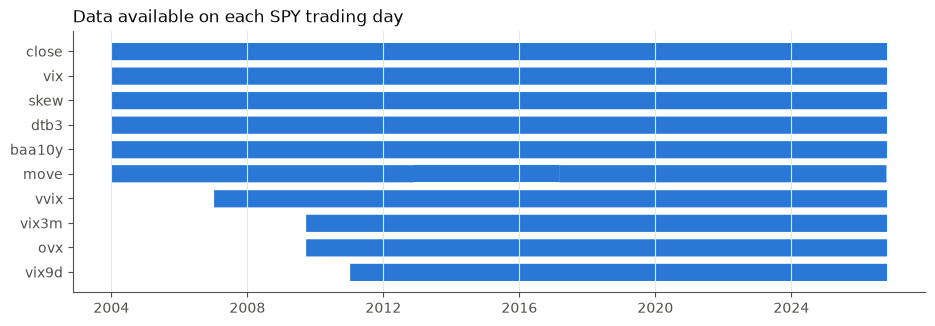

In [3]:
columns = ["close", "vix", "skew", "dtb3", "baa10y", "move", "vvix", "vix3m", "ovx", "vix9d"]
fig, ax = plt.subplots(figsize=(11, 3.4))
for row, column in enumerate(columns):
    present = daily[column].notna()
    ax.fill_between(daily.index, row - 0.35, row + 0.35, where=present, color=BLUE, linewidth=0)
ax.set_yticks(range(len(columns)), columns)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.set_title("Data available on each SPY trading day")
plt.show()

## 3. Integrity checks

In [4]:
returns = np.log(daily["close"]).diff()

print("Duplicate dates:          ", daily.index.duplicated().sum())
print("Dates strictly increasing:", daily.index.is_monotonic_increasing)
print("Non-positive prices:      ", (daily[["open", "high", "low", "close"]] <= 0).sum().sum())
print("High below low:           ", (daily["high"] < daily["low"]).sum())
print("Close outside high-low:   ", ((daily["close"] > daily["high"] * 1.0001) | (daily["close"] < daily["low"] * 0.9999)).sum())
print("Missing VIX:              ", daily["vix"].isna().sum())

gaps = daily.index.to_series().diff().dt.days
print("Gaps longer than 4 days:  ", gaps[gaps > 4].to_dict())

Duplicate dates:           0
Dates strictly increasing: True
Non-positive prices:       0
High below low:            0
Close outside high-low:    0
Missing VIX:               0
Gaps longer than 4 days:   {Timestamp('2007-01-03 00:00:00'): 5.0, Timestamp('2012-10-31 00:00:00'): 5.0}


Biggest daily moves should be known crisis days.

In [5]:
largest = returns.abs().nlargest(8).index
pd.DataFrame({"SPY log return": returns[largest].round(4), "VIX": daily.loc[largest, "vix"]}).sort_index()

,SPY log return,VIX
Date,,
2008-10-13,0.1356,54.99
2008-10-15,-0.1036,69.25
2008-10-28,0.1105,66.96
2008-12-01,-0.0927,68.51
2020-03-12,-0.1006,75.47
2020-03-16,-0.1159,82.69
2020-03-24,0.0867,61.67
2025-04-09,0.0999,33.62


## 4. Plots

VIX vs past 21-day realized vol (just a sanity check, the real target is built in Stage 2).

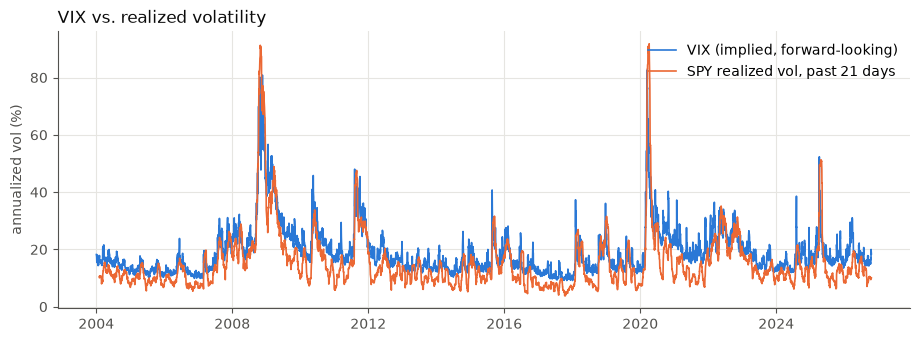

Share of days VIX > past realized vol: 86%


In [6]:
realized_vol = np.sqrt(returns.pow(2).rolling(21).sum() * 252 / 21) * 100

fig, ax = plt.subplots()
ax.plot(daily.index, daily["vix"], color=BLUE, label="VIX (implied, forward-looking)")
ax.plot(daily.index, realized_vol, color=ORANGE, label="SPY realized vol, past 21 days")
ax.set_ylabel("annualized vol (%)")
ax.set_title("VIX vs. realized volatility")
ax.legend(frameon=False, loc="upper right")
plt.show()

print(f"Share of days VIX > past realized vol: {(daily['vix'] > realized_vol).mean():.0%}")

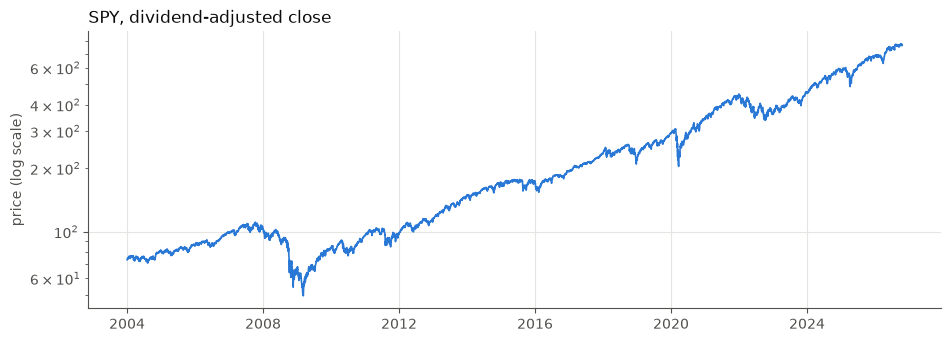

In [7]:
fig, ax = plt.subplots()
ax.plot(daily.index, daily["close"], color=BLUE)
ax.set_yscale("log")
ax.set_ylabel("price (log scale)")
ax.set_title("SPY, dividend-adjusted close")
plt.show()

Other series.

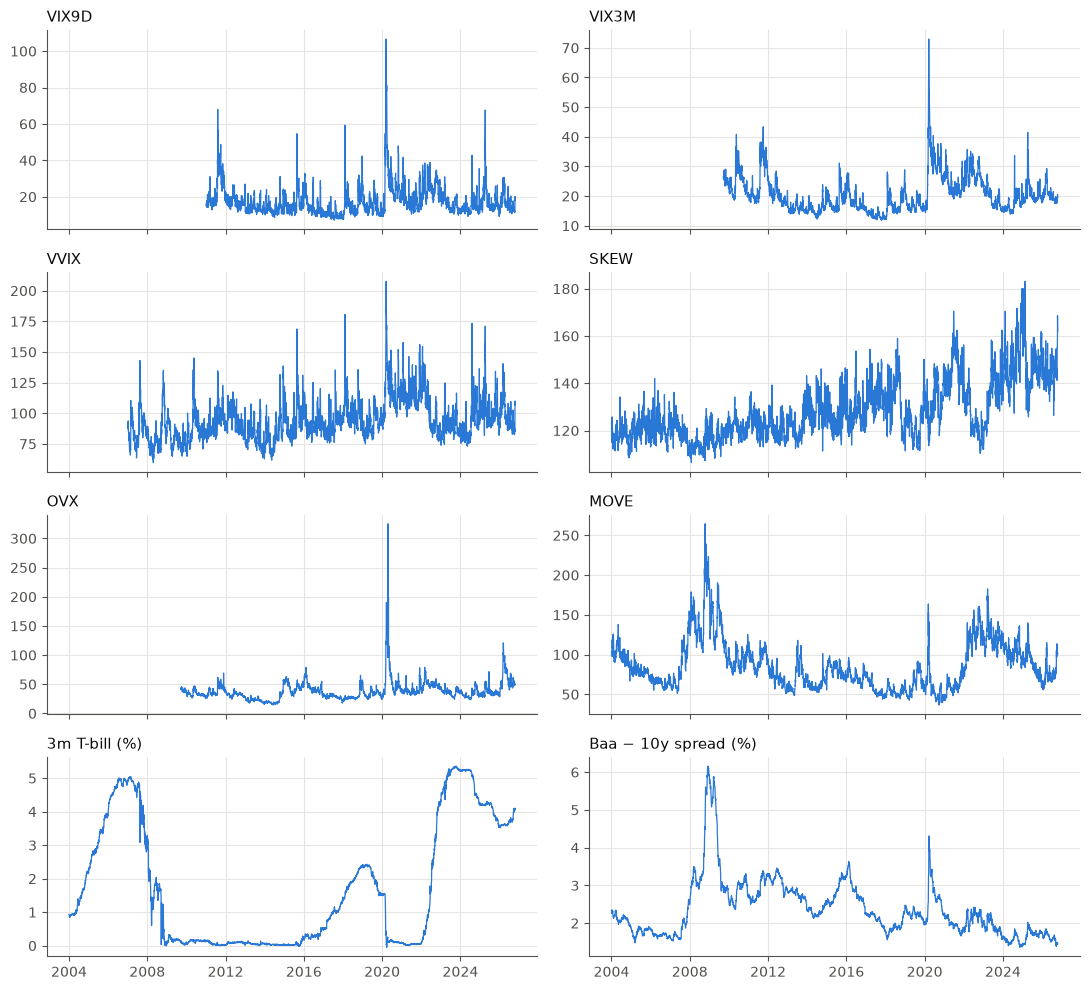

In [8]:
others = {
    "vix9d": "VIX9D", "vix3m": "VIX3M", "vvix": "VVIX", "skew": "SKEW",
    "ovx": "OVX", "move": "MOVE", "dtb3": "3m T-bill (%)", "baa10y": "Baa − 10y spread (%)",
}
fig, axes = plt.subplots(4, 2, figsize=(11, 10), sharex=True)
for ax, (column, title) in zip(axes.flat, others.items()):
    ax.plot(daily.index, daily[column], color=BLUE, linewidth=0.9)
    ax.set_title(title, fontsize=11)
fig.tight_layout()
plt.show()

## 5. Findings

TODO